In [14]:
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import tensorflow as tf
import os
import splitfolders
import seaborn as sns
from PIL import Image
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.applications import MobileNetV2, VGG16, InceptionResNetV2
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import layers, models

In [2]:
os.listdir("./Dataset")

['test_data', 'train_data']

In [3]:
base_dir = "./Dataset"

train_dir = os.path.join(base_dir, "train_data")
test_dir = os.path.join(base_dir, "test_data")

In [5]:
# ImageDataGenerator Setup
train_datagen = ImageDataGenerator(
    rescale=1/255.0,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Generator untuk test/evaluasi hanya di-rescale saja (tanpa augmentasi)
test_datagen = ImageDataGenerator(rescale=1/255.0)

# Flow from Directory
train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=True
)

test_gen = test_datagen.flow_from_directory(
    test_dir,                      # Menggunakan test_dir
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False                  # Diset False agar urutan data konsisten saat evaluasi
)

Found 1269 images belonging to 3 classes.
Found 315 images belonging to 3 classes.


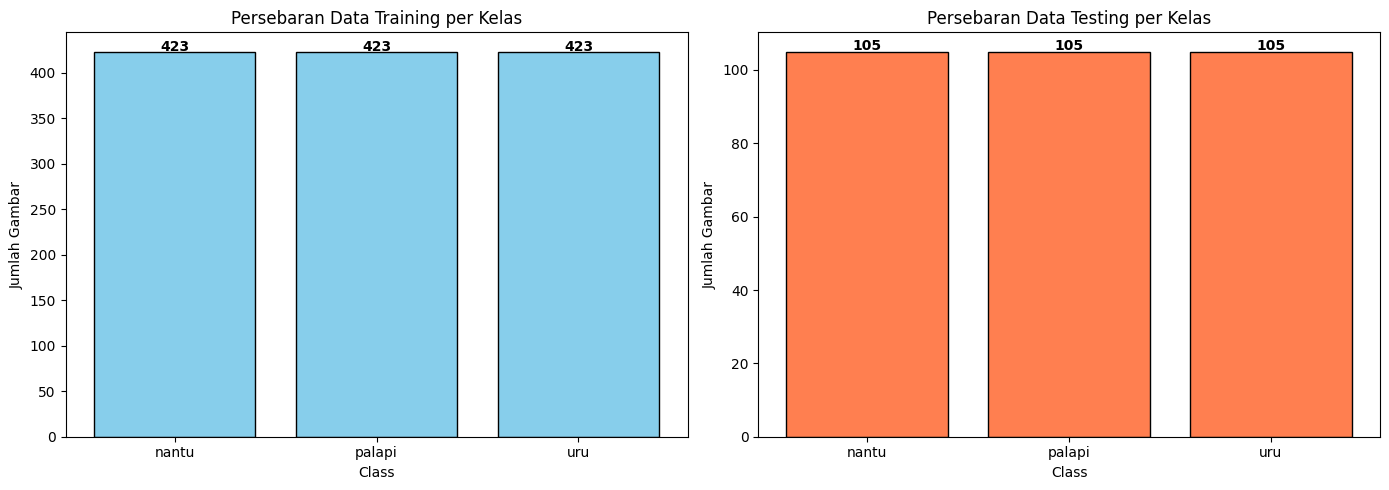

In [ ]:
# Ambil label kelas dari generator
nama_class = list(train_gen.class_indices.keys())

# Hitung jumlah gambar per kelas
jumlah_train = np.unique(train_gen.classes, return_counts=True)[1]
jumlah_test = np.unique(test_gen.classes, return_counts=True)[1]

# Plotting side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1 Data Training
axes[0].bar(nama_class, jumlah_train, color='skyblue', edgecolor='black')
axes[0].set_title("Persebaran Data Training per Kelas")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Jumlah Gambar")
for i, v in enumerate(jumlah_train):
    axes[0].text(i, v + 0.5, str(v), ha='center', fontweight='bold')

# Subplot 2 Data Testing
axes[1].bar(nama_class, jumlah_test, color='coral', edgecolor='black')
axes[1].set_title("Persebaran Data Testing per Kelas")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Jumlah Gambar")
for i, v in enumerate(jumlah_test):
    axes[1].text(i, v + 0.5, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

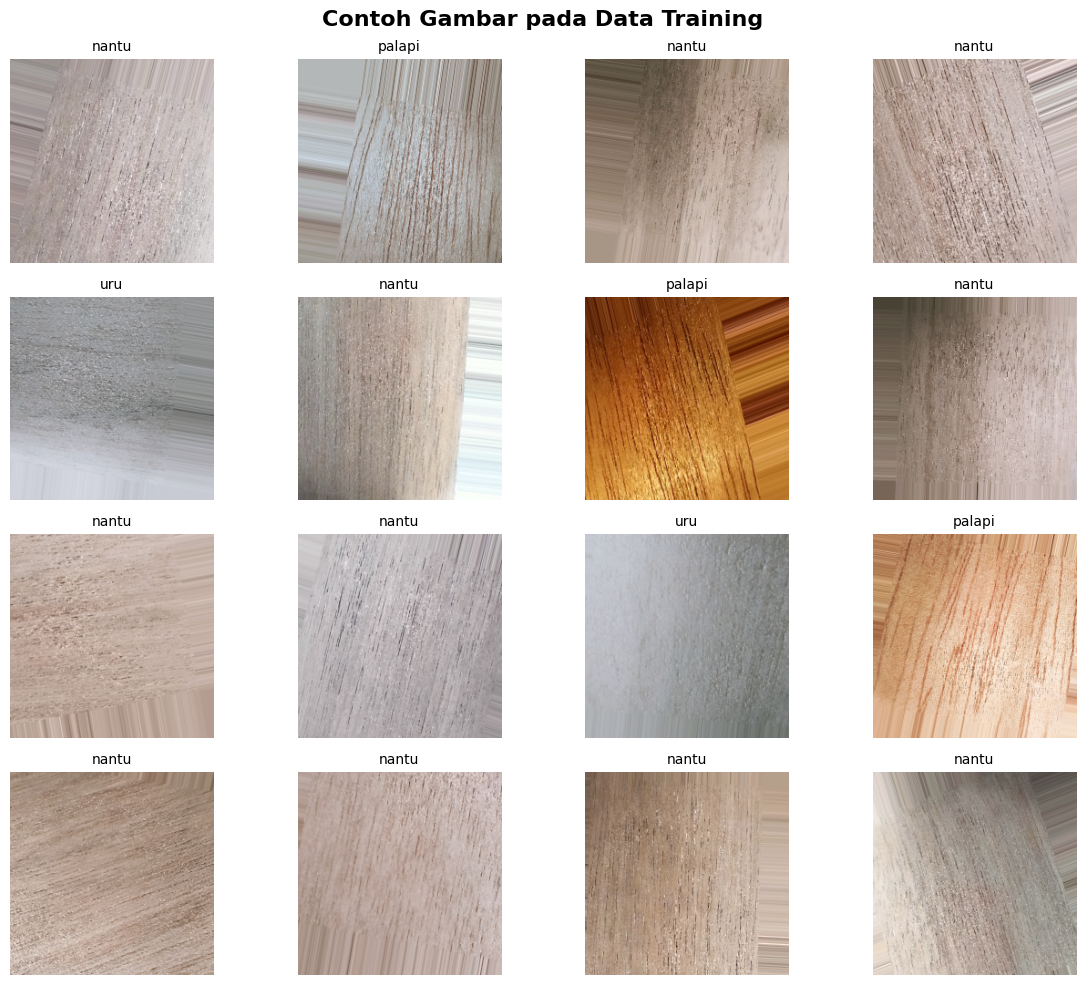

In [7]:
# Ambil batch gambar & label berikutnya
X_batch, y_batch = next(train_gen)

# Ambil daftar nama kelas secara otomatis dari generator (nantu, palapi, uru)
daftar_label = list(train_gen.class_indices.keys())

# Plot 16 gambar (grid 4x4)
fig, axes = plt.subplots(4, 4, figsize=(12, 10))
fig.suptitle("Contoh Gambar pada Data Training", fontsize=16, fontweight='bold')

for i, ax in enumerate(axes.flatten()):
    ax.imshow(X_batch[i])
    ax.axis('off')
    
    # Ambil index kelas (apakah one-hot encoded atau sparse)
    class_idx = int(y_batch[i]) if y_batch.ndim == 1 else int(y_batch[i].argmax())
    true_label = daftar_label[class_idx]
    
    ax.set_title(true_label, fontsize=10)

plt.tight_layout()
plt.show()

In [16]:
reduce_on_plateau = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',   # Tetap monitor val_loss (karena validation_data=test_gen di model.fit)
    factor=0.2,           # Mengurangi Learning Rate jadi 20% (misal 0.001 -> 0.0002). 0.2 seringkali lebih halus dibanding 0.1
    patience=3,           # Menunggu 3 epoch tanpa penurunan loss sebelum LR dikurangi
    verbose=1,            # DIUBAH ke 1 agar muncul notifikasi log di terminal/notebook saat LR turun
    mode='auto',
    min_delta=0.0001,
    cooldown=1,           # DIUBAH ke 1 (cooldown=3 agak terlalu lama menahan perubahan LR setelah dikurangi)
    min_lr=1e-6           # DIUBAH ke 1e-6 (1e-8 terlalu kecil, biasanya weights tidak lagi update signifikan pada 1e-8)
)

In [17]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',         # DIUBAH: Menggunakan val_loss biasanya lebih stabil dibanding val_accuracy
    min_delta=0.001,            # DIUBAH: Minimal perbaikan loss sebesar 0.001 (mencegah komputasi sia-sia jika stagnan)
    patience=5,                 # Menunggu 5 epoch tanpa ada perbaikan sebelum berhenti
    mode='min',                 # DIUBAH: 'min' karena memantau loss (mencari nilai terkecil)
    baseline=None,
    restore_best_weights=True,  # Mengembalikan bobot model ke performa terbaik sebelum overfitting
    verbose=1                   # DITAMBAHKAN: Agar muncul notifikasi di terminal/notebook saat training berhenti awal
)

In [ ]:
def buatReport(model, test_generator, class_labels):
    # Reset generator ke awal
    test_generator.reset()

    # Evaluasi model (Loss & Accuracy)
    test_loss, test_acc = model.evaluate(test_generator, verbose=1)
    print(f"\nLoss Evaluasi: {test_loss:.4f}")
    print(f"Akurasi Evaluasi: {test_acc * 100:.2f}%\n")

    # Prediksi seluruh data test secara langsung (otomatis menangani batch)
    test_generator.reset()
    y_pred_probs = model.predict(test_generator, verbose=1)
    all_pred_classes = np.argmax(y_pred_probs, axis=1)
    all_true_classes = test_generator.classes

    # Confusion Matrix
    cm = confusion_matrix(all_true_classes, all_pred_classes)
    print("Confusion Matrix:")
    print(cm)
    print()

    # Visualisasi Heatmap Confusion Matrix
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_labels, yticklabels=class_labels)
    plt.title("Confusion Matrix Evaluasi Model")
    plt.xlabel("Prediksi")
    plt.ylabel("Aktual")
    plt.show()

    # Classification Report
    report = classification_report(all_true_classes, all_pred_classes, target_names=class_labels)
    print("Classification Report:")
    print(report)

    # Visualisasi 16 Sampel Prediksi
    test_generator.reset()
    X_batch, y_batch = next(test_generator)
    preds = model.predict(X_batch, verbose=0)

    pred_classes = np.argmax(preds, axis=1)
    true_classes = np.argmax(y_batch, axis=1)

    fig, axes = plt.subplots(4, 4, figsize=(13, 10))
    fig.suptitle(f"Hasil Prediksi Sample (Akurasi Total: {test_acc * 100:.2f}%)", fontsize=14, fontweight='bold')

    for i, ax in enumerate(axes.flatten()):
        # X_batch sudah di-rescale 1/255.0, imshow bisa membaca langsung float 0-1
        ax.imshow(X_batch[i])
        ax.axis('off')

        true_label = class_labels[int(true_classes[i])]
        pred_label = class_labels[int(pred_classes[i])]

        font_color = 'green' if true_label == pred_label else 'red'
        ax.set_title(f"Label: {true_label}\nPred: {pred_label}", color=font_color, fontsize=9)

    plt.tight_layout()
    plt.show()

Epoch 1/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 41s 990ms/step - accuracy: 0.6391 - loss: 0.8703 - val_accuracy: 0.8063 - val_loss: 0.4287 - learning_rate: 0.0010
Epoch 2/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 43s 1s/step - accuracy: 0.8424 - loss: 0.3993 - val_accuracy: 0.8571 - val_loss: 0.3511 - learning_rate: 0.0010
Epoch 3/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 36s 906ms/step - accuracy: 0.8227 - loss: 0.4428 - val_accuracy: 0.8762 - val_loss: 0.2821 - learning_rate: 0.0010
Epoch 4/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 36s 897ms/step - accuracy: 0.8826 - loss: 0.3302 - val_accuracy: 0.9079 - val_loss: 0.2272 - learning_rate: 0.0010
Epoch 5/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 36s 895ms/step - accuracy: 0.7667 - loss: 0.5700 - val_accuracy: 0.9048 - val_loss: 0.4417 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 4.
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 284ms/step - accuracy: 0.9079 - loss: 0.2272

Loss Evaluasi: 0.2272
Akurasi Evaluasi: 90.79%

10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 288ms/step
Confusion Matrix:
[

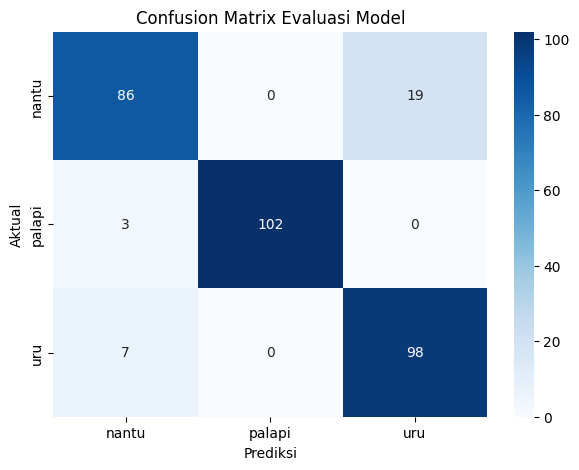

Classification Report:
              precision    recall  f1-score   support

       nantu       0.90      0.82      0.86       105
      palapi       1.00      0.97      0.99       105
         uru       0.84      0.93      0.88       105

    accuracy                           0.91       315
   macro avg       0.91      0.91      0.91       315
weighted avg       0.91      0.91      0.91       315



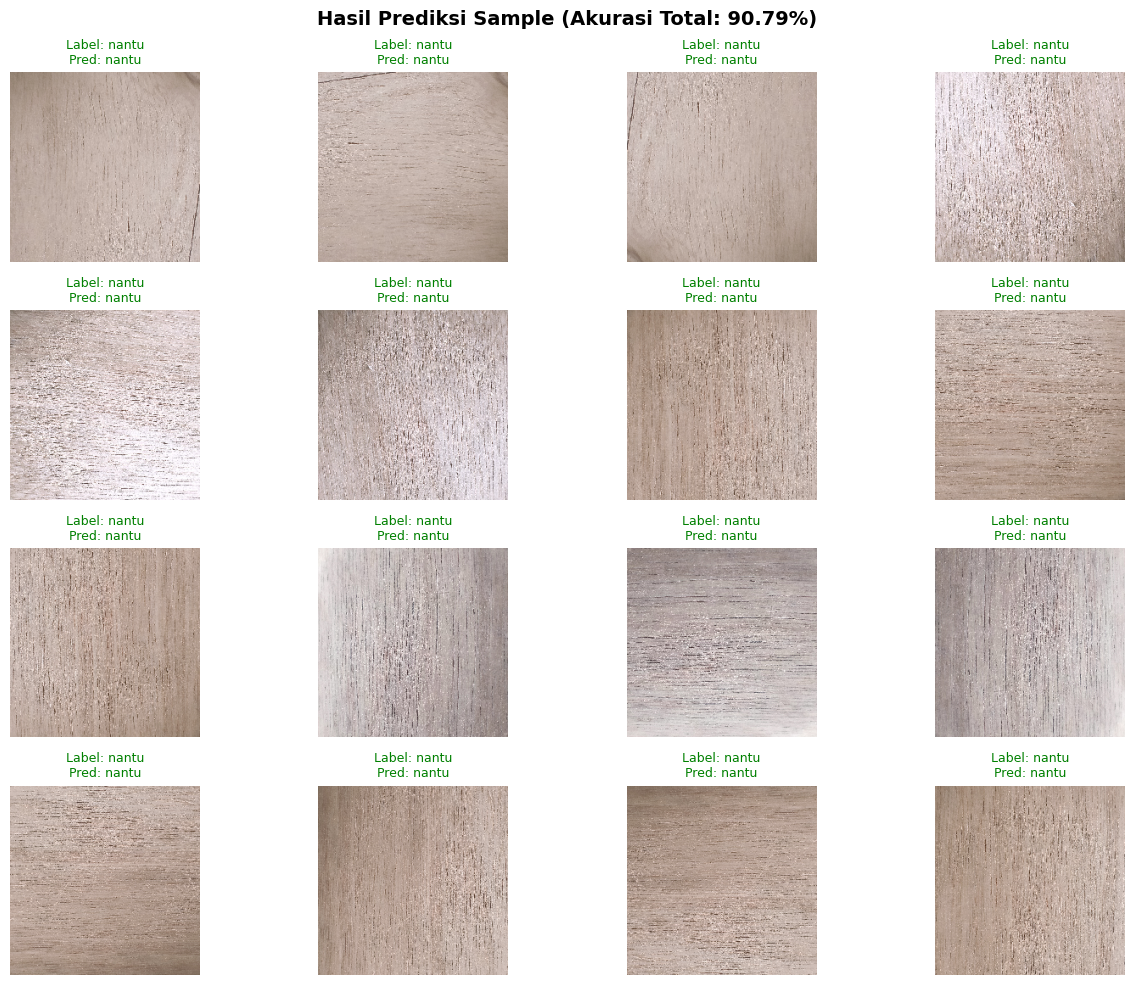

In [19]:
# Buat Arsitektur Model CNN
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(3, activation='softmax')  # 3 output neuron untuk 3 kelas
])

# Compile Model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Training Model
history = model.fit(
    train_gen,
    epochs=5,
    validation_data=test_gen,
    callbacks=[reduce_on_plateau, early_stop]
)

# Panggil Fungsi Report
daftar_label = list(test_gen.class_indices.keys())
buatReport(model, test_gen, daftar_label)

In [20]:
def buatGrafik(hist):
    loss = hist.history['loss']
    val_loss = hist.history['val_loss']
    accuracy = hist.history['accuracy']
    val_accuracy = hist.history['val_accuracy']
    epochs = range(1, len(loss) + 1)

    plt.figure(figsize=(14, 5))

    # Plot Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, 'bo-', label='Training Loss')
    plt.plot(epochs, val_loss, 'ro-', label='Validation/Test Loss')
    plt.title('Training and Test Loss', fontsize=12, fontweight='bold')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()

    # Plot Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, 'bo-', label='Training Accuracy')
    plt.plot(epochs, val_accuracy, 'ro-', label='Validation/Test Accuracy')
    plt.title('Training and Test Accuracy', fontsize=12, fontweight='bold')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()

    plt.tight_layout()
    plt.show()

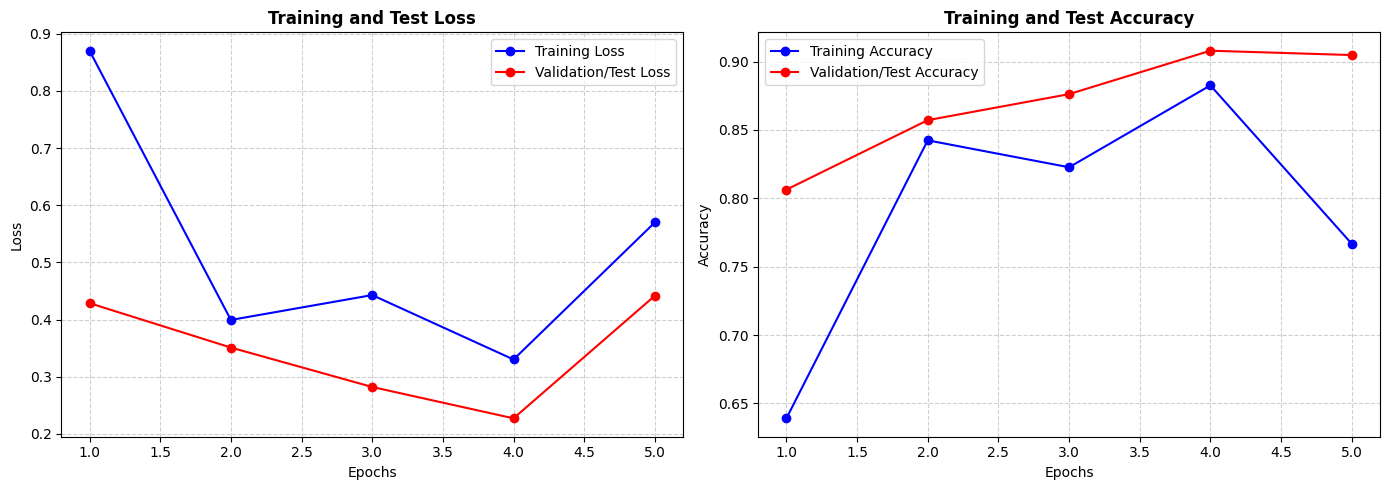

In [22]:
buatGrafik(history)